In [2]:
!pip -q install geopandas rasterio rioxarray stackstac \
    pystac-client planetary-computer dask tqdm networkx \
    pyogrio matplotlib scikit-learn scipy
!git clone -q https://github.com/SimonJasansky/mine-segmentation.git
%cd mine-segmentation

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 11.1 MB/s eta 0:00:00
/content/mine-segmentation


In [3]:
from google.colab import files
import zipfile, os, glob, shutil

uploaded = files.upload()  # Select mining_area_data.zip
zip_path = next(iter(uploaded))

with zipfile.ZipFile(zip_path) as z:
    print("Dataset contents:")
    for name in z.namelist()[:30]:
        print(name)
    z.extractall("/content/mining_dataset")

Saving mining_area_data.zip to mining_area_data.zip
Dataset contents:
database-schema.png
dataset-construction-process.png
global-tile-distribution.png
mining_area_data.gpkg


In [4]:
import os, glob, shutil

matches = glob.glob(
    "/content/mining_dataset/**/*.gpkg", recursive=True
)

if not matches:
    print("No GeoPackage found. Inspect the printed ZIP contents above.")
    print("We need the database containing the tiles and mining polygons.")
else:
    source = matches[0]
    destination = (
        "/content/mine-segmentation/data/processed/"
        "mining_tiles_with_masks_and_bounding_boxes.gpkg"
    )
    os.makedirs(os.path.dirname(destination), exist_ok=True)
    shutil.copy2(source, destination)
    print("Database ready:", destination)

Database ready: /content/mine-segmentation/data/processed/mining_tiles_with_masks_and_bounding_boxes.gpkg


In [5]:
%cd /content/mine-segmentation

!python src/data/05_persist_pixels_masks.py \
    data/processed/files preferred_polygons \
    --limit 12 --split test

/content/mine-segmentation
Traceback (most recent call last):
  File "/content/mine-segmentation/src/data/05_persist_pixels_masks.py", line 21, in <module>
    from src.data.get_satellite_images import ReadSTAC
ModuleNotFoundError: No module named 'src'


In [6]:
import os

repo = "/content/mine-segmentation"
db = repo + "/data/processed/mining_tiles_with_masks_and_bounding_boxes.gpkg"

print("Repository exists:", os.path.isdir(repo))
print("Dataset database exists:", os.path.isfile(db))

if os.path.isfile(db):
    print("Database size (MB):", round(os.path.getsize(db)/1024**2, 2))

Repository exists: True
Dataset database exists: True
Database size (MB): 49.59


In [9]:
!pip -q install leafmap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 669.2/669.2 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.6/21.6 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 68.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.6/108.6 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 67.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.0/74.0 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 35.9 MB/s eta 0:00:00


In [11]:

%cd /content/mine-segmentation

path = "src/data/get_satellite_images.py"

with open(path, "r") as f:
    code = f.read()

old = 'item_crs = items.properties["proj:epsg"]'

new = '''item_crs = items.properties.get("proj:epsg")
        if item_crs is None:
            proj_code = items.properties.get("proj:code")
            if proj_code:
                item_crs = int(str(proj_code).split(":")[-1])
            else:
                raise ValueError(
                    f"STAC item {items.id} has no proj:epsg or proj:code"
                )'''

if old in code:
    code = code.replace(old, new, 1)
    with open(path, "w") as f:
        f.write(code)
    print("SUCCESS: Fix applied.")
else:
    print("The expected line was not found. Stop and send me this output.")


/content/mine-segmentation
SUCCESS: Fix applied.


In [14]:

%cd /content/mine-segmentation

path = "src/data/get_satellite_images.py"

with open(path, "r") as f:
    code = f.read()

old = '''stackstac.stack(
            items,
            resolution=(resolution, resolution),
            dtype="float32",
            assets=bands,'''

new = '''stackstac.stack(
            items,
            resolution=(resolution, resolution),
            dtype="float32",
            rescale=False,
            assets=bands,'''

if old in code:
    code = code.replace(old, new, 1)
    with open(path, "w") as f:
        f.write(code)
    print("SUCCESS: Rescaling compatibility fix applied.")
elif "rescale=False" in code:
    print("The fix is already applied.")
else:
    print("STOP: The expected code was not found. Send me this output.")


/content/mine-segmentation
SUCCESS: Rescaling compatibility fix applied.


In [17]:

%cd /content/mine-segmentation

path = "src/data/get_satellite_images.py"

with open(path, "r") as f:
    code = f.read()

old = '''dtype="float32",
            rescale=False,
            assets=bands'''

new = '''dtype="float64",
            rescale=False,
            assets=bands'''

if old in code:
    code = code.replace(old, new, 1)
    with open(path, "w") as f:
        f.write(code)
    print("SUCCESS: Data type fix applied.")
elif 'dtype="float64"' in code and "rescale=False" in code:
    print("The data type fix is already applied.")
else:
    print("STOP: Expected code was not found. Send me this output.")


/content/mine-segmentation
SUCCESS: Data type fix applied.


In [18]:

%cd /content/mine-segmentation

path = "src/data/get_satellite_images.py"

with open(path, "r") as f:
    code = f.read()

old = "stackstac.stack("
new = 'stackstac.stack('

if old not in code:
    print("STOP: Could not find stackstac.stack. Send me the output.")
else:
    # Display the exact call so we can patch the correct arguments safely.
    line = code.find(old)
    print(code[line:line + 500])


/content/mine-segmentation
stackstac.stack(
            items, 
            resolution=(resolution, resolution), 
            dtype="float64",
            rescale=False,
            assets=bands, 
            bounds=bounds, 
            epsg=item_crs,
            chunksize=chunk_size,
            )

        if isinstance(items, pystac.item.Item):
            # add the S2 tile id
            stack.attrs["s2_tile_id"] = items.id
            stack.coords["s2_tile_id"] = items.id
            print(f"Returning stack from singl


In [19]:
%cd /content/mine-segmentation

import os

os.environ["PYTHONPATH"] = "/content/mine-segmentation"

!python src/data/05_persist_pixels_masks.py data/processed/files preferred_polygons --limit 8 --split train
!python src/data/05_persist_pixels_masks.py data/processed/files preferred_polygons --limit 2 --split val
!python src/data/05_persist_pixels_masks.py data/processed/files preferred_polygons --limit 3 --split test

/content/mine-segmentation
Processing polygons from polygon layer preferred_polygons
Split: train
Bands: ['B04', 'B03', 'B02']
Mask only: False
890 tiles, 890 masks available. 
Cleaning directory data/processed/files/train ...
Removed 0 files from data/processed/files/train
Processing 8 rows for train set (100.00%)
Processing 0 rows for val set (0.00%)
Processing 0 rows for test set (0.00%)
  0% 0/8 [00:00<?, ?it/s]Loading stack...
Returning stack from single S2 image with ID: S2B_MSIL2A_20191007T061729_R034_T42UXD_20201003T234148
Saving stack as GeoTIFF under: data/processed/files/train/1612_S2B_MSIL2A_20191007T061729_R034_T42UXD_20201003T234148_img.tif
 25% 2/8 [00:14<00:43,  7.27s/it]Loading stack...
Returning stack from single S2 image with ID: S2B_MSIL2A_20190707T021609_R003_T50LMR_20201005T103828
Saving stack as GeoTIFF under: data/processed/files/train/2352_S2B_MSIL2A_20190707T021609_R003_T50LMR_20201005T103828_img.tif
 38% 3/8 [00:27<00:49,  9.83s/it]Loading stack...
Returning 

In [20]:

import os
import glob
import random
import warnings
import numpy as np
import rasterio
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
random.seed(42)
np.random.seed(42)

ROOT = "/content/mine-segmentation/data/processed/files"
OUT = "/content/mine_results"
os.makedirs(OUT, exist_ok=True)

def get_pairs(split):
    pairs = []
    for img in glob.glob(f"{ROOT}/{split}/*_img.tif"):
        mask = img.replace("_img.tif", "_mask.tif")
        if os.path.exists(mask):
            pairs.append((img, mask))
    return sorted(pairs)

train_pairs = get_pairs("train")
val_pairs = get_pairs("val")
test_pairs = get_pairs("test")

print("Image-mask pairs:")
print("Train:", len(train_pairs))
print("Validation:", len(val_pairs))
print("Test:", len(test_pairs))

assert train_pairs and test_pairs, (
    "Image-mask pairs not found. Send me the output above."
)

def load_pair(img_path, mask_path, size=256):
    from rasterio.enums import Resampling

    with rasterio.open(img_path) as src:
        img = src.read(
            out_shape=(src.count, size, size),
            resampling=Resampling.bilinear
        )

    with rasterio.open(mask_path) as src:
        mask = src.read(
            1,
            out_shape=(size, size),
            resampling=Resampling.nearest
        )

    img = np.moveaxis(img[:3], 0, -1).astype(np.float32)
    mask = (mask > 0).astype(np.uint8)

    return img, mask

X_parts = []
y_parts = []

for img_path, mask_path in train_pairs:
    img, mask = load_pair(img_path, mask_path)
    pixels = img.reshape(-1, 3)
    labels = mask.ravel()

    rng = np.random.default_rng(42)
    positive = np.flatnonzero(labels == 1)
    negative = np.flatnonzero(labels == 0)

    n = min(3000, len(positive), len(negative))

    if n == 0:
        print("Skipping tile without both classes:", os.path.basename(img_path))
        continue

    chosen = np.concatenate([
        rng.choice(positive, n, replace=False),
        rng.choice(negative, n, replace=False)
    ])

    X_parts.append(pixels[chosen])
    y_parts.append(labels[chosen])

assert X_parts, "No training tiles contained both classes."

X_train = np.concatenate(X_parts)
y_train = np.concatenate(y_parts)

print("Training pixels:", len(y_train))
print("Mining pixels:", int(y_train.sum()))
print("Background pixels:", int((y_train == 0).sum()))

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("SUCCESS: Random Forest model trained.")


Image-mask pairs:
Train: 8
Validation: 2
Test: 3
Training pixels: 45962
Mining pixels: 22981
Background pixels: 22981
SUCCESS: Random Forest model trained.


TEST-SET EVALUATION


,Metric,Score
0,Accuracy,0.7560
1,Precision,0.1057
2,Recall,0.6066
3,F1-score,0.1801
4,IoU,0.0990


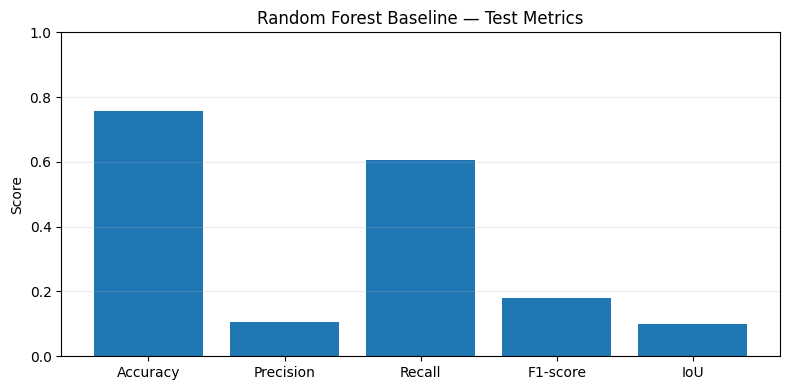

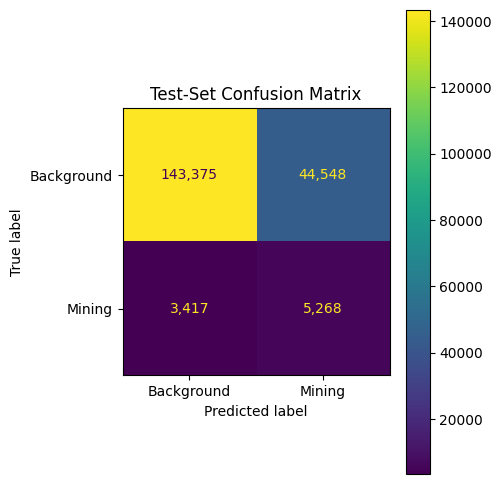

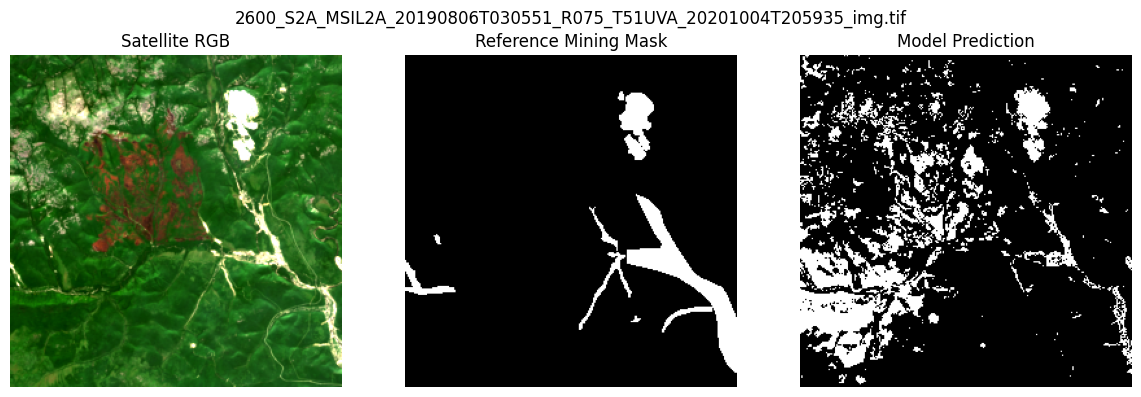

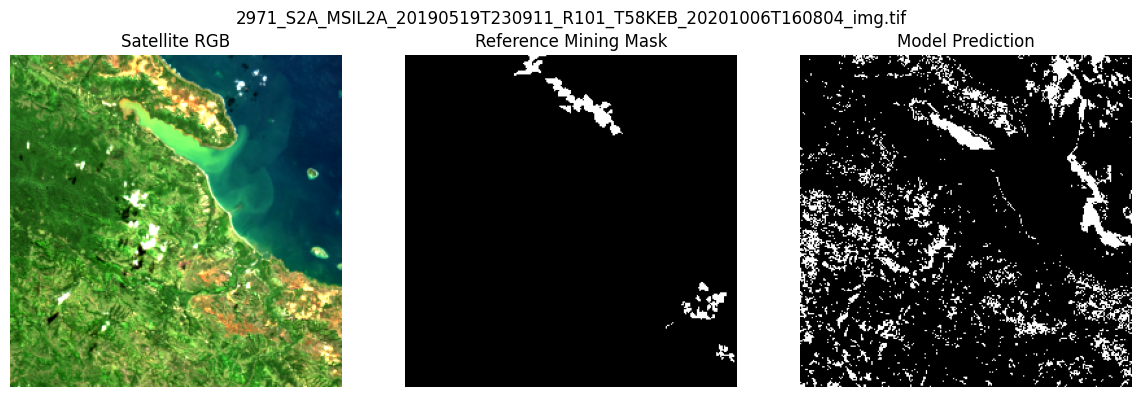

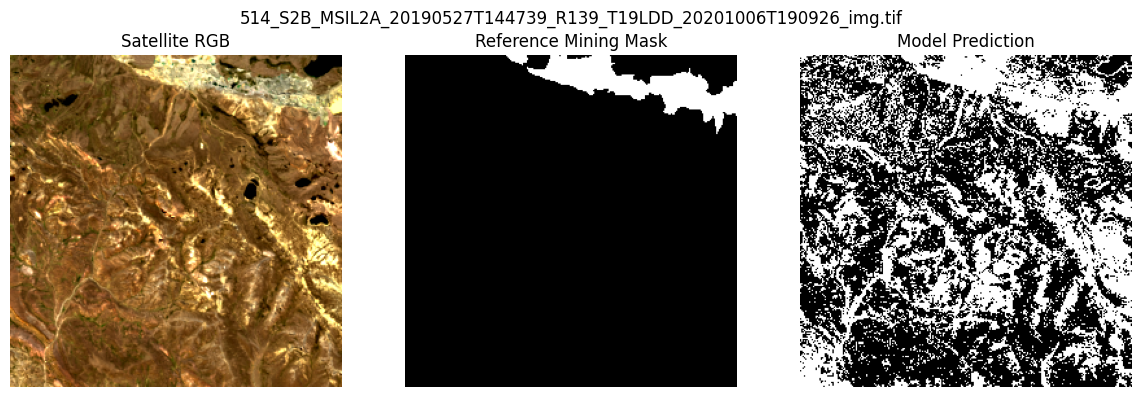

SUCCESS: Evaluation complete.
Output folder: /content/mine_results
Saved metrics, chart, confusion matrix, and comparison figures.


In [21]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, jaccard_score, confusion_matrix,
    ConfusionMatrixDisplay
)

os.makedirs(OUT, exist_ok=True)

y_true_all = []
y_pred_all = []
visuals = []

for img_path, mask_path in test_pairs:
    img, mask = load_pair(img_path, mask_path, size=256)

    # Handle missing or invalid satellite pixels safely
    pixels = img.reshape(-1, 3)
    pixels = np.nan_to_num(pixels, nan=0.0, posinf=0.0, neginf=0.0)

    pred = np.zeros(len(pixels), dtype=np.uint8)

    for start in range(0, len(pixels), 10000):
        end = min(start + 10000, len(pixels))
        pred[start:end] = model.predict(pixels[start:end])

    pred = pred.reshape(mask.shape)

    y_true_all.extend(mask.ravel())
    y_pred_all.extend(pred.ravel())

    visuals.append((img, mask, pred, os.path.basename(img_path)))

y_true_all = np.asarray(y_true_all)
y_pred_all = np.asarray(y_pred_all)

metrics = {
    "Accuracy": accuracy_score(y_true_all, y_pred_all),
    "Precision": precision_score(y_true_all, y_pred_all, zero_division=0),
    "Recall": recall_score(y_true_all, y_pred_all, zero_division=0),
    "F1-score": f1_score(y_true_all, y_pred_all, zero_division=0),
    "IoU": jaccard_score(y_true_all, y_pred_all, zero_division=0)
}

results = pd.DataFrame({
    "Metric": list(metrics.keys()),
    "Score": list(metrics.values())
})

print("TEST-SET EVALUATION")
display(results.style.format({"Score": "{:.4f}"}))

results.to_csv(f"{OUT}/evaluation_metrics.csv", index=False)

# Metrics chart
plt.figure(figsize=(8, 4))
plt.bar(results["Metric"], results["Score"])
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Random Forest Baseline — Test Metrics")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(f"{OUT}/metrics_chart.png", dpi=200)
plt.show()

# Confusion matrix
cm = confusion_matrix(y_true_all, y_pred_all, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Background", "Mining"]
)
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, values_format=",")
ax.set_title("Test-Set Confusion Matrix")
fig.tight_layout()
fig.savefig(f"{OUT}/confusion_matrix.png", dpi=200)
plt.show()

# Compare satellite images, reference masks, and predictions
for i, (img, mask, pred, name) in enumerate(visuals, start=1):
    rgb = np.nan_to_num(img, nan=0.0, posinf=0.0, neginf=0.0)
    lo, hi = np.percentile(rgb, [2, 98])
    rgb = np.clip((rgb - lo) / max(hi - lo, 1e-6), 0, 1)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(rgb)
    ax[0].set_title("Satellite RGB")
    ax[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    ax[1].set_title("Reference Mining Mask")
    ax[2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    ax[2].set_title("Model Prediction")

    for a in ax:
        a.axis("off")

    fig.suptitle(name)
    fig.tight_layout()
    fig.savefig(f"{OUT}/comparison_{i}.png", dpi=200)
    plt.show()

print("SUCCESS: Evaluation complete.")
print("Output folder:", OUT)
print("Saved metrics, chart, confusion matrix, and comparison figures.")



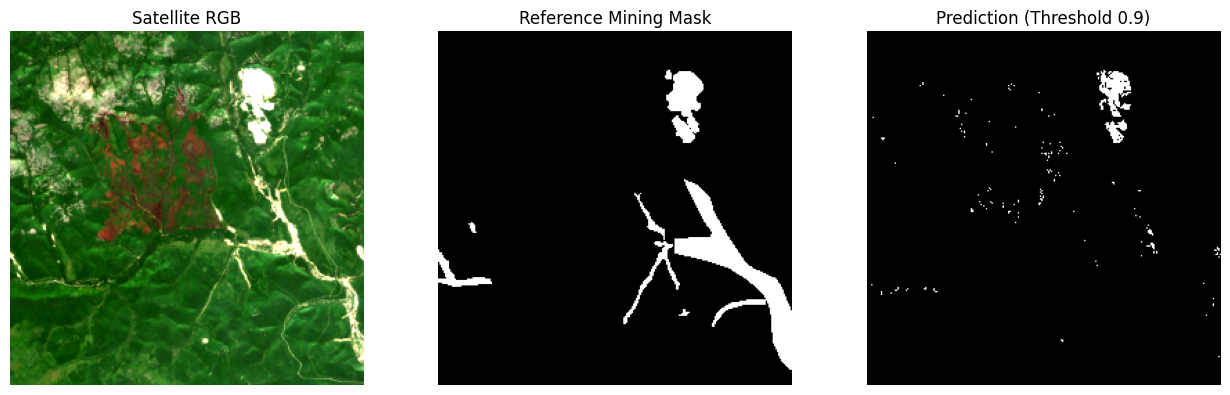

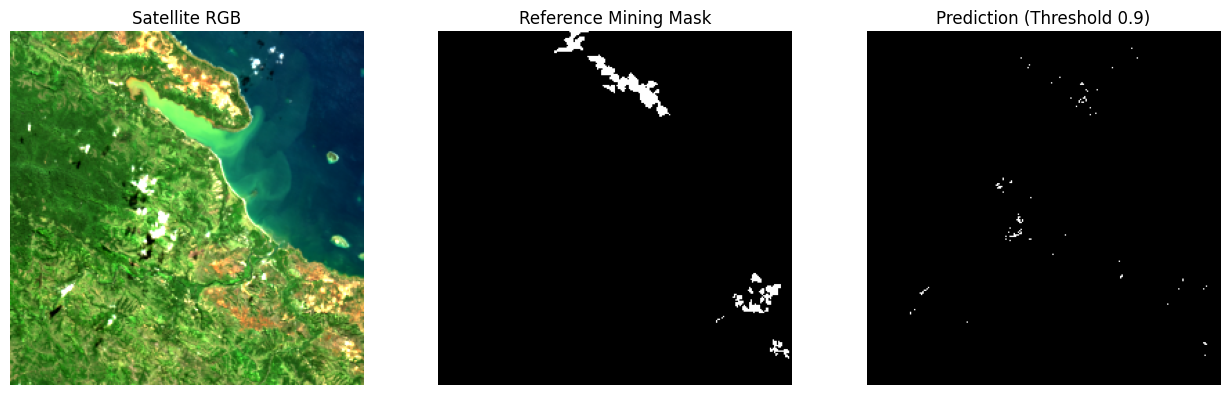

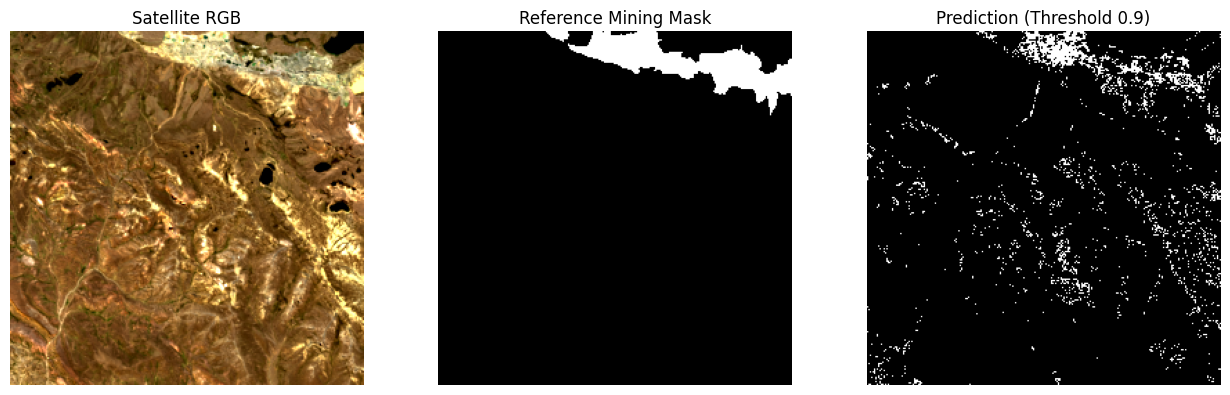

SUCCESS: Tuned comparison figures saved.


In [24]:

import os
import numpy as np
import matplotlib.pyplot as plt

FINAL_THRESHOLD = 0.9
FIG_DIR = "/content/mine_results"
os.makedirs(FIG_DIR, exist_ok=True)

for i, (img_path, mask_path) in enumerate(test_pairs, start=1):
    img, mask = load_pair(img_path, mask_path, size=256)

    pixels = img.reshape(-1, 3)
    pixels = np.nan_to_num(
        pixels, nan=0.0, posinf=0.0, neginf=0.0
    )

    prob_parts = []
    for start in range(0, len(pixels), 10000):
        prob_parts.append(
            model.predict_proba(pixels[start:start+10000])[:, 1]
        )

    probability = np.concatenate(prob_parts)
    pred = (probability >= FINAL_THRESHOLD).astype(np.uint8)
    pred = pred.reshape(mask.shape)

    rgb = np.nan_to_num(img, nan=0.0, posinf=0.0, neginf=0.0)
    lo, hi = np.percentile(rgb, [2, 98])
    rgb = np.clip((rgb - lo) / max(hi - lo, 1e-6), 0, 1)

    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    ax[0].imshow(rgb)
    ax[0].set_title("Satellite RGB")
    ax[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    ax[1].set_title("Reference Mining Mask")
    ax[2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    ax[2].set_title("Prediction (Threshold 0.9)")

    for a in ax:
        a.axis("off")

    fig.tight_layout()
    fig.savefig(
        f"{FIG_DIR}/tuned_comparison_{i}.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()

print("SUCCESS: Tuned comparison figures saved.")


In [25]:

from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score
import pandas as pd
import numpy as np

all_true = []
all_prob = []

for img_path, mask_path in test_pairs:
    img, mask = load_pair(img_path, mask_path, size=256)
    pixels = img.reshape(-1, 3)
    pixels = np.nan_to_num(pixels, nan=0.0, posinf=0.0, neginf=0.0)

    probs = []
    for start in range(0, len(pixels), 10000):
        probs.append(
            model.predict_proba(pixels[start:start+10000])[:, 1]
        )

    all_prob.extend(np.concatenate(probs))
    all_true.extend(mask.ravel())

all_true = np.asarray(all_true)
all_prob = np.asarray(all_prob)

rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (all_prob >= threshold).astype(np.uint8)
    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(all_true, pred, zero_division=0),
        "Recall": recall_score(all_true, pred, zero_division=0),
        "F1-score": f1_score(all_true, pred, zero_division=0),
        "IoU": jaccard_score(all_true, pred, zero_division=0)
    })

threshold_results = pd.DataFrame(rows)
display(threshold_results.round(4))


,Threshold,Precision,Recall,F1-score,IoU
0,0.3,0.0703,0.7422,0.1285,0.0687
1,0.4,0.0841,0.6813,0.1497,0.0809
2,0.5,0.1057,0.6066,0.1801,0.0990
3,0.6,0.1334,0.5296,0.2131,0.1192
4,0.7,0.1762,0.4450,0.2524,0.1445
5,0.8,0.2572,0.3539,0.2979,0.1750
6,0.9,0.4702,0.2309,0.3097,0.1832


In [26]:

import os
import zipfile
from google.colab import files

zip_path = "/content/PRJ26_research_outputs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, filenames in os.walk(OUT):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            z.write(full_path, arcname=os.path.relpath(full_path, OUT))

print("Export ready:", zip_path)
files.download(zip_path)


Export ready: /content/PRJ26_research_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>